<a href="https://colab.research.google.com/github/EliasLA79/Van_der_pol_PINN/blob/main/Van_der_pol_PINN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ============================================================
# Control Total
# ============================================================

hidden, layers, n_frequencies = 20, 3, 10

guardar = False #Guardar imágenes
SEED = 10

n_data_points = 50
selection_mode = "uniform" #"uniform" o "random"
EPOCHS_PINN = 5000

In [3]:
# @title
# ============================================================
# 1. Librerías y dispositivo CPU/GPU
# ============================================================
import time
import math
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import os
import shutil

# Ray Tune para búsqueda de hiperparámetros
import ray
from ray import tune
from ray.tune.schedulers import ASHAScheduler

# Reproducibilidad
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Dispositivo automático
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo usado:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Usamos float32 porque es más rápido en GPU y suficiente para este caso
torch.set_default_dtype(torch.float32)

Dispositivo usado: cpu


In [4]:
# @title
# ============================================================
# 2. Parámetros del problema
# ============================================================
# Ecuación general:
# x' = y
# y' = mu*(1 - x^2)*y - alpha*x - beta*x^3 - gamma*x^5

mu = 0.2

# Condiciones iniciales
x0 = 0.1
y0 = 0.1

# Intervalo temporal
# Si tarda mucho o no aprende bien, prueba primero con t_total = 20 o 50.
t_total = 100.0
N = 2000

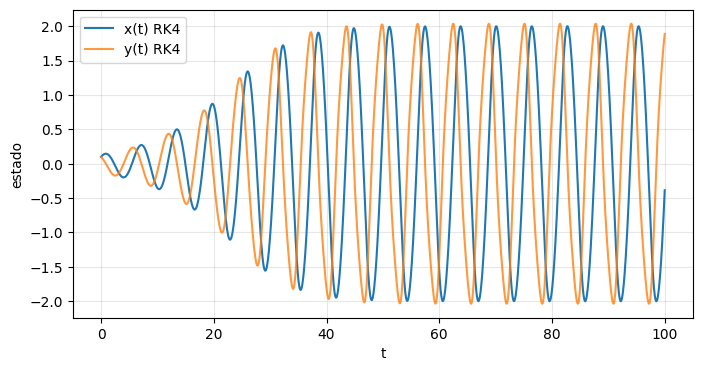

In [5]:
# @title
# ============================================================
# 3. Sistema y solución de referencia RK4
# ============================================================
def f_rhs(x, y):
    return y


def g_rhs(x, y):
    return mu * (1.0 - x**2) * y - ((mu**2)/16)*(x**3)*(x**2-4)-x


def rk4_vanderpol(x0, y0, t_total, N):
    dt = t_total / (N - 1)
    t = torch.linspace(0.0, t_total, N)
    x = torch.zeros(N)
    y = torch.zeros(N)

    x[0] = x0
    y[0] = y0

    for i in range(N - 1):
        xi = x[i]
        yi = y[i]

        k1 = dt * f_rhs(xi, yi)
        l1 = dt * g_rhs(xi, yi)

        k2 = dt * f_rhs(xi + k1 / 2.0, yi + l1 / 2.0)
        l2 = dt * g_rhs(xi + k1 / 2.0, yi + l1 / 2.0)

        k3 = dt * f_rhs(xi + k2 / 2.0, yi + l2 / 2.0)
        l3 = dt * g_rhs(xi + k2 / 2.0, yi + l2 / 2.0)

        k4 = dt * f_rhs(xi + k3, yi + l3)
        l4 = dt * g_rhs(xi + k3, yi + l3)

        x[i + 1] = xi + (k1 + 2*k2 + 2*k3 + k4) / 6.0
        y[i + 1] = yi + (l1 + 2*l2 + 2*l3 + l4) / 6.0

    return t, x, y


tlist, xlist, ylist = rk4_vanderpol(x0, y0, t_total, N)

plt.figure(figsize=(8, 4))
plt.plot(tlist.numpy(), xlist.numpy(), label="x(t) RK4")
plt.plot(tlist.numpy(), ylist.numpy(), label="y(t) RK4", alpha=0.8)
plt.xlabel("t")
plt.ylabel("estado")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
# @title
# ============================================================
# 4. Datos para entrenamiento y normalización temporal
# ============================================================
def normalize_t(t):
    # Convierte t en [0, t_total] a tau en [-1, 1]
    return 2.0 * (t / t_total) - 1.0


def denormalize_tau(tau):
    # Convierte tau en [-1, 1] a t en [0, t_total]
    return 0.5 * (tau + 1.0) * t_total

n_data_points = min(n_data_points,N)

if selection_mode == "uniform":
  idx = torch.linspace(
      0,
      N-1,
      steps = n_data_points
  ).round().long()

elif selection_mode == "random":
  generator = torch.Generator()
  generator.manual_seed(SEED)

  idx = torch.randperm(N,generator=generator)[:n_data_points]
  idx = torch.sort(idx).values

else:
  raise ValueError("selection_mode debe ser 'uniform' o 'random'")


# Datos en CPU -> GPU/CPU según device
t_raw = tlist[idx].reshape(-1, 1).to(device)
tau_train = normalize_t(t_raw).to(device)
x_train = xlist[idx].reshape(-1, 1).to(device)
y_train = ylist[idx].reshape(-1, 1).to(device)

# Condición inicial en tau = -1 porque t = 0
tau0 = torch.tensor([[-1.0]], dtype=torch.float32, device=device)
x0_tensor = torch.tensor([[x0]], dtype=torch.float32, device=device)
y0_tensor = torch.tensor([[y0]], dtype=torch.float32, device=device)

# Factor de regla de la cadena:
# tau = 2t/t_total - 1  -> d/dt = (2/t_total) d/dtau
dtau_dt = 2.0 / t_total


In [7]:
# @title
# ============================================================
# 5. Modelo PINN con características de Fourier
# ============================================================
class FourierMLP(nn.Module):
    def __init__(self, hidden=128, layers=4, n_frequencies=24):
        super().__init__()
        self.n_frequencies = n_frequencies
        self.register_buffer(
            "freqs",
            torch.arange(1, n_frequencies + 1, dtype=torch.float32).view(1, -1)
        )

        input_dim = 1 + 2 * n_frequencies  # tau + sin + cos

        net = []
        net.append(nn.Linear(input_dim, hidden))
        net.append(nn.Tanh())

        for _ in range(layers - 1):
            net.append(nn.Linear(hidden, hidden))
            net.append(nn.Tanh())

        net.append(nn.Linear(hidden, 2))  # salida: [x_pred, y_pred]
        self.net = nn.Sequential(*net)

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_normal_(module.weight)
            nn.init.zeros_(module.bias)

    def features(self, tau):
        # tau está en [-1, 1]. Definimos s en [0, 1]
        s = 0.5 * (tau + 1.0)
        angles = 2.0 * math.pi * s * self.freqs
        return torch.cat([tau, torch.sin(angles), torch.cos(angles)], dim=1)

    def forward(self, tau):
        z = self.features(tau)
        return self.net(z)




model = FourierMLP(hidden, layers, n_frequencies).to(device)

print(model)
print("Parámetros entrenables:", sum(p.numel() for p in model.parameters() if p.requires_grad))

FourierMLP(
  (net): Sequential(
    (0): Linear(in_features=21, out_features=20, bias=True)
    (1): Tanh()
    (2): Linear(in_features=20, out_features=20, bias=True)
    (3): Tanh()
    (4): Linear(in_features=20, out_features=20, bias=True)
    (5): Tanh()
    (6): Linear(in_features=20, out_features=2, bias=True)
  )
)
Parámetros entrenables: 1322


In [8]:
# @title
# ============================================================
# 6. Pérdidas: datos, física e inicial
# ============================================================
def split_pred(pred):
    x_pred = pred[:, 0:1]
    y_pred = pred[:, 1:2]
    return x_pred, y_pred


def mse(a, b):
    return torch.mean((a - b)**2)


def data_loss(model):
    pred = model(tau_train)
    x_pred, y_pred = split_pred(pred)
    return mse(x_pred, x_train) + mse(y_pred, y_train)


def initial_loss(model):
    pred0 = model(tau0)
    x0_pred, y0_pred = split_pred(pred0)
    return mse(x0_pred, x0_tensor) + mse(y0_pred, y0_tensor)


def physics_loss(model, tau_col):
    # Necesitamos derivadas respecto a tau
    tau_col = tau_col.clone().detach().requires_grad_(True)

    pred = model(tau_col)
    x_pred, y_pred = split_pred(pred)

    dx_dtau = torch.autograd.grad(
        x_pred,
        tau_col,
        grad_outputs=torch.ones_like(x_pred),
        create_graph=True
    )[0]

    dy_dtau = torch.autograd.grad(
        y_pred,
        tau_col,
        grad_outputs=torch.ones_like(y_pred),
        create_graph=True
    )[0]

    # Regla de la cadena para volver a derivadas respecto a t
    dx_dt = dx_dtau * dtau_dt
    dy_dt = dy_dtau * dtau_dt

    # Sistema de Van der Pol generalizado
    rhs_x = y_pred
    rhs_y = mu * (1.0 - x_pred**2) * y_pred - ((mu**2)/16)*(x_pred**3)*(x_pred**2-4)-x_pred

    r1 = dx_dt - rhs_x
    r2 = dy_dt - rhs_y

    return torch.mean(r1**2) + torch.mean(r2**2)

In [9]:
# @title
# ============================================================
# 7. Configuración de entrenamiento
# ============================================================
LR = 1e-3
N_COLLOCATION = 2000

# Pesos de la pérdida total
lambda_data = 10
lambda_physics = 1.0
lambda_initial = 10.0

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-6)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=4000, gamma=0.5)

history = {
    "epoch": [],
    "loss_total": [],
    "loss_data": [],
    "loss_physics": [],
    "loss_initial": []
}

In [10]:
# ============================================================
# 8. Búsqueda de hiperparámetros con Ray Tune + entrenamiento final
# ============================================================

# Ray Tune hará una búsqueda preliminar con menos épocas por ensayo.
# Después se reentrena la mejor configuración durante EPOCHS_PINN.
TUNE_EPOCHS = 3000
TUNE_REPORT_EVERY = 250
TUNE_NUM_SAMPLES = 12
TUNE_MAX_CONCURRENT_TRIALS = 1  # aumentar solo si hay recursos suficientes
TUNE_COLLOCATION = min(N_COLLOCATION, 1000)


# Métrica de validación: RMSE combinado de x(t) e y(t) sobre la trayectoria RK4.
# Se usa para comparar configuraciones; los puntos de entrenamiento siguen siendo
# los definidos en la sección 4.
@torch.no_grad()
def validation_rmse(model):
    model.eval()
    tau_val = normalize_t(tlist.reshape(-1, 1)).to(device)
    pred = model(tau_val)
    x_val, y_val = split_pred(pred)
    x_ref = xlist.reshape(-1, 1).to(device)
    y_ref = ylist.reshape(-1, 1).to(device)
    rmse_x_val = torch.sqrt(torch.mean((x_val - x_ref) ** 2))
    rmse_y_val = torch.sqrt(torch.mean((y_val - y_ref) ** 2))
    # Promedio de ambos RMSE para dar igual peso a las dos variables.
    return ((rmse_x_val + rmse_y_val) / 2.0).item()


def trainable_pinn(config):
    # Cada ensayo construye un modelo independiente.
    trial_model = FourierMLP(
        hidden=config["hidden"],
        layers=config["layers"],
        n_frequencies=config["n_frequencies"]
    ).to(device)

    trial_optimizer = optim.AdamW(
        trial_model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"]
    )
    trial_scheduler = optim.lr_scheduler.StepLR(
        trial_optimizer,
        step_size=max(500, TUNE_EPOCHS // 3),
        gamma=config["scheduler_gamma"]
    )

    for epoch in range(1, TUNE_EPOCHS + 1):
        trial_model.train()
        trial_optimizer.zero_grad(set_to_none=True)

        tau_col = 2.0 * torch.rand(TUNE_COLLOCATION, 1, device=device) - 1.0

        l_data = data_loss(trial_model)
        l_phys = physics_loss(trial_model, tau_col)
        l_init = initial_loss(trial_model)

        loss = (
            config["lambda_data"] * l_data
            + config["lambda_physics"] * l_phys
            + config["lambda_initial"] * l_init
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(trial_model.parameters(), max_norm=1.0)
        trial_optimizer.step()
        trial_scheduler.step()

        if epoch % TUNE_REPORT_EVERY == 0 or epoch == TUNE_EPOCHS:
            val_rmse = validation_rmse(trial_model)
            # Ray Tune usa el último reporte para el scheduler y la selección.
            tune.report({
                "val_rmse": val_rmse,
                "loss_total": loss.item(),
                "loss_data": l_data.item(),
                "loss_physics": l_phys.item(),
                "loss_initial": l_init.item(),
                "training_iteration": epoch
            })


# Ray se ejecuta localmente. En GPU, cada ensayo solicita una GPU; en CPU,
# se solicita un núcleo. Se usa un ensayo concurrente por defecto para evitar
# saturar Colab y competir por la memoria de la GPU.
if ray.is_initialized():
    ray.shutdown()

ray.init(
    ignore_reinit_error=True,
    include_dashboard=False,
    log_to_driver=False
)

search_space = {
    "lr": tune.loguniform(1e-4, 3e-3),
    "weight_decay": tune.loguniform(1e-8, 1e-4),
    "hidden": tune.choice([32, 64, 96, 128]),
    "layers": tune.choice([2, 3, 4]),
    "n_frequencies": tune.choice([16, 24, 32, 48]),
    "lambda_data": tune.loguniform(1.0, 30.0),
    "lambda_physics": tune.loguniform(0.1, 10.0),
    "lambda_initial": tune.loguniform(1.0, 30.0),
    "scheduler_gamma": tune.choice([0.3, 0.5, 0.7])
}

asha = ASHAScheduler(
    metric="val_rmse",
    mode="min",
    max_t=TUNE_EPOCHS,
    grace_period=TUNE_REPORT_EVERY * 2,
    reduction_factor=2
)

trainable = tune.with_resources(
    trainable_pinn,
    resources={"cpu": 1, "gpu": 1 if device.type == "cuda" else 0}
)

analysis = tune.run(
    trainable,
    config=search_space,
    num_samples=TUNE_NUM_SAMPLES,
    scheduler=asha,
    resources_per_trial=None,
    max_concurrent_trials=TUNE_MAX_CONCURRENT_TRIALS,
    name="vdp_pinn_tuning",
    trial_dirname_creator=lambda trial: f"t_{trial.trial_id}",
    verbose=1
)

best_config = analysis.get_best_config(metric="val_rmse", mode="min")
best_trial = analysis.get_best_trial(metric="val_rmse", mode="min", scope="last")
best_result = best_trial.last_result

print("\nMejor configuración encontrada:")
for key, value in best_config.items():
    print(f"  {key}: {value}")
print(f"Mejor RMSE de validación reportado: {best_result['val_rmse']:.6e}")

2026-10-28 17:21:38,373	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to 'C:/Users/Elías/ray_results/vdp_pinn_tuning' in 0.4424s.
2026-10-28 17:21:38,456	INFO tune.py:1039 -- Total run time: 726.72 seconds (726.05 seconds for the tuning loop).



Mejor configuración encontrada:
  lr: 0.0003091934846903452
  weight_decay: 1.7321817627492422e-06
  hidden: 96
  layers: 2
  n_frequencies: 32
  lambda_data: 1.4735630523036634
  lambda_physics: 4.543208336879831
  lambda_initial: 1.1729285301671346
  scheduler_gamma: 0.3
Mejor RMSE de validación reportado: 6.003696e-04


In [11]:
# ------------------------------------------------------------
# 9. Entrenamiento final con la mejor configuración
# ------------------------------------------------------------
hidden = best_config["hidden"]
layers = best_config["layers"]
n_frequencies = best_config["n_frequencies"]
LR = best_config["lr"]
lambda_data = best_config["lambda_data"]
lambda_physics = best_config["lambda_physics"]
lambda_initial = best_config["lambda_initial"]

model = FourierMLP(hidden, layers, n_frequencies).to(device)
optimizer = optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=best_config["weight_decay"]
)
scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=4000,
    gamma=best_config["scheduler_gamma"]
)

history = {
    "epoch": [],
    "loss_total": [],
    "loss_data": [],
    "loss_physics": [],
    "loss_initial": []
}

if torch.cuda.is_available():
    torch.cuda.synchronize()
inicio = time.perf_counter()

for epoch in range(1, EPOCHS_PINN + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    tau_col = 2.0 * torch.rand(N_COLLOCATION, 1, device=device) - 1.0
    l_data = data_loss(model)
    l_phys = physics_loss(model, tau_col)
    l_init = initial_loss(model)

    loss = lambda_data * l_data + lambda_physics * l_phys + lambda_initial * l_init

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()

    history["epoch"].append(epoch)
    history["loss_total"].append(loss.item())
    history["loss_data"].append(l_data.item())
    history["loss_physics"].append(l_phys.item())
    history["loss_initial"].append(l_init.item())

    if epoch % 500 == 0 or epoch == 1:
        print(
            f"[PINN final] epoch {epoch:5d} | "
            f"total={loss.item():.6e} | "
            f"data={l_data.item():.6e} | "
            f"phys={l_phys.item():.6e} | "
            f"init={l_init.item():.6e}"
        )

if torch.cuda.is_available():
    torch.cuda.synchronize()
fin = time.perf_counter()
tiempo_entrenamiento = fin - inicio

minutos = int(tiempo_entrenamiento // 60)
segundos = tiempo_entrenamiento % 60
print(f"Tiempo del entrenamiento final: {minutos} min {segundos:.2f} s")

# Tabla de resultados de los ensayos de Ray Tune
df_tuning = analysis.results_df
display(df_tuning.sort_values("val_rmse").head(10))

[PINN final] epoch     1 | total=1.749736e+01 | data=3.978096e+00 | phys=2.508077e+00 | init=2.051915e-01
[PINN final] epoch   500 | total=1.292530e-03 | data=1.986490e-05 | phys=2.544259e-04 | init=9.152119e-05
[PINN final] epoch  1000 | total=3.230032e-04 | data=3.343148e-06 | phys=6.790040e-05 | init=8.177174e-06
[PINN final] epoch  1500 | total=2.339970e-04 | data=2.848793e-06 | phys=4.361318e-05 | init=2.698827e-05
[PINN final] epoch  2000 | total=4.697236e-04 | data=1.143279e-05 | phys=3.602533e-05 | init=2.465676e-04
[PINN final] epoch  2500 | total=9.189689e-05 | data=1.330053e-06 | phys=1.731499e-05 | init=9.609597e-06
[PINN final] epoch  3000 | total=8.685896e-05 | data=1.793956e-06 | phys=1.502484e-05 | init=1.360228e-05
[PINN final] epoch  3500 | total=6.654193e-05 | data=1.402557e-06 | phys=1.297291e-05 | init=4.720277e-06
[PINN final] epoch  4000 | total=1.061026e-04 | data=2.917206e-06 | phys=1.146122e-05 | init=4.240090e-05
[PINN final] epoch  4500 | total=3.318879e-05 

,val_rmse,loss_total,loss_data,loss_physics,loss_initial,training_iteration,timestamp,checkpoint_dir_name,done,date,...,experiment_tag,config/lr,config/weight_decay,config/hidden,config/layers,config/n_frequencies,config/lambda_data,config/lambda_physics,config/lambda_initial,config/scheduler_gamma
trial_id,,,,,,,,,,,,,,,,,,,,,
a225d_00004,0.000600,0.000215,6.272605e-07,0.000047,0.000001,3000,1793229345,None,True,2026-10-28_17-15-45,...,"4_hidden=96,lambda_data=1.4736,lambda_initial=...",0.000309,1.732182e-06,96,2,32,1.473563,4.543208,1.172929,0.3
a225d_00000,0.000917,0.000115,1.859887e-06,0.000053,0.000006,3000,1793229058,None,True,2026-10-28_17-10-58,...,"0_hidden=32,lambda_data=16.9369,lambda_initial...",0.001378,1.210620e-08,32,3,48,16.936901,1.467721,1.089386,0.7
a225d_00007,0.001699,0.000352,3.552621e-06,0.000067,0.000060,2000,1793229526,None,True,2026-10-28_17-18-46,...,"7_hidden=96,lambda_data=3.8606,lambda_initial=...",0.000472,2.016004e-05,96,3,24,3.860648,1.887570,3.550235,0.5
a225d_00009,0.004646,0.001077,8.821684e-06,0.000490,0.000143,1000,1793229594,None,True,2026-10-28_17-19-54,...,"9_hidden=32,lambda_data=6.6381,lambda_initial=...",0.000871,2.428782e-07,32,3,24,6.638116,1.115891,3.299194,0.5
a225d_00011,0.006501,0.013363,7.282264e-05,0.004362,0.001717,1000,1793229697,None,True,2026-10-28_17-21-37,...,"11_hidden=64,lambda_data=27.9148,lambda_initia...",0.000361,9.779753e-06,64,4,48,27.914803,0.477987,5.385758,0.7
a225d_00002,0.008154,0.005453,1.519919e-04,0.000711,0.001223,1000,1793229145,None,True,2026-10-28_17-12-25,...,"2_hidden=96,lambda_data=6.3300,lambda_initial=...",0.001979,8.123479e-06,96,3,24,6.330002,0.192460,3.560160,0.7
a225d_00006,0.012281,0.023458,7.757036e-05,0.004668,0.001634,500,1793229418,None,True,2026-10-28_17-16-58,...,"6_hidden=96,lambda_data=17.5770,lambda_initial...",0.000175,3.716353e-07,96,3,32,17.576981,2.080044,7.577684,0.7
a225d_00005,0.014493,0.025585,5.191842e-04,0.002138,0.001067,500,1793229378,None,True,2026-10-28_17-16-18,...,"5_hidden=64,lambda_data=2.8680,lambda_initial=...",0.001623,6.248707e-08,64,2,48,2.868004,1.567345,19.437009,0.3
a225d_00003,0.019139,0.051556,9.421805e-04,0.003698,0.002396,1000,1793229204,None,True,2026-10-28_17-13-24,...,"3_hidden=64,lambda_data=9.1351,lambda_initial=...",0.001660,2.640021e-08,64,2,48,9.135146,1.592494,15.467221,0.3


In [12]:
"""
# @title
# ============================================================
# 8. Entrenamiento PINN
# ============================================================
if torch.cuda.is_available():
    torch.cuda.synchronize()

inicio = time.perf_counter()

for epoch in range(1, EPOCHS_PINN + 1):
    optimizer.zero_grad(set_to_none=True)

    # Puntos de colocación aleatorios en tau ∈ [-1, 1]
    tau_col = 2.0 * torch.rand(N_COLLOCATION, 1, device=device) - 1.0

    l_data = data_loss(model)
    l_phys = physics_loss(model, tau_col)
    l_init = initial_loss(model)

    loss = lambda_data * l_data + lambda_physics * l_phys + lambda_initial * l_init

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()

    history["epoch"].append(epoch)
    history["loss_total"].append(loss.item())
    history["loss_data"].append(l_data.item())
    history["loss_physics"].append(l_phys.item())
    history["loss_initial"].append(l_init.item())

    if epoch % 1000 == 0 or epoch == 1:
        print(
            f"[PINN] epoch {epoch:5d} | "
            f"total={loss.item():.6e} | "
            f"data={l_data.item():.6e} | "
            f"phys={l_phys.item():.6e} | "
            f"init={l_init.item():.6e}"
        )

if torch.cuda.is_available():
    torch.cuda.synchronize()

fin = time.perf_counter()

tiempo_entrenamiento = fin - inicio

minutos = int(tiempo_entrenamiento // 60)
segundos = tiempo_entrenamiento % 60

print(f"{minutos} min {segundos:.2f} s")
"""

'\n# @title\n# ============================================================\n# 8. Entrenamiento PINN\n# ============================================================\nif torch.cuda.is_available():\n    torch.cuda.synchronize()\n\ninicio = time.perf_counter()\n\nfor epoch in range(1, EPOCHS_PINN + 1):\n    optimizer.zero_grad(set_to_none=True)\n\n    # Puntos de colocación aleatorios en tau ∈ [-1, 1]\n    tau_col = 2.0 * torch.rand(N_COLLOCATION, 1, device=device) - 1.0\n\n    l_data = data_loss(model)\n    l_phys = physics_loss(model, tau_col)\n    l_init = initial_loss(model)\n\n    loss = lambda_data * l_data + lambda_physics * l_phys + lambda_initial * l_init\n\n    loss.backward()\n    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)\n    optimizer.step()\n    scheduler.step()\n\n    history["epoch"].append(epoch)\n    history["loss_total"].append(loss.item())\n    history["loss_data"].append(l_data.item())\n    history["loss_physics"].append(l_phys.item())\n    hist

RMSE x: 2,75083e-04
RMSE y: 3,07909e-04


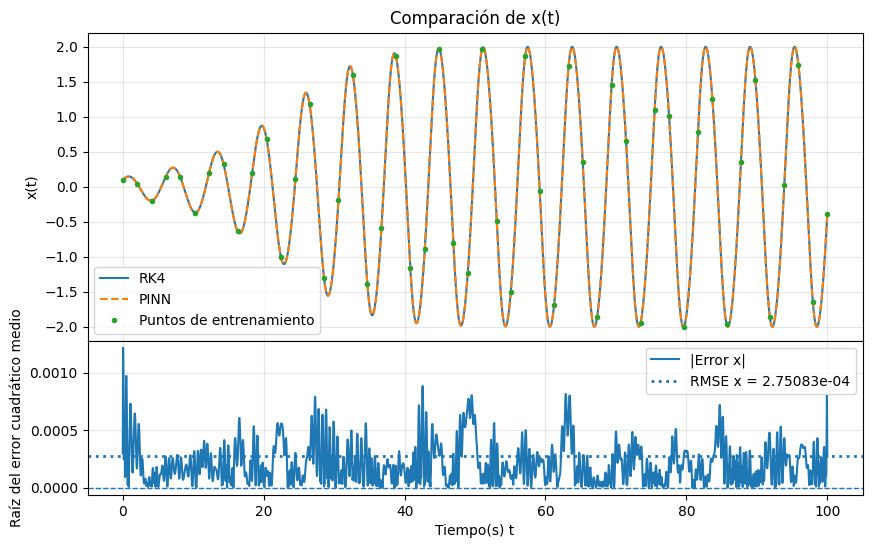

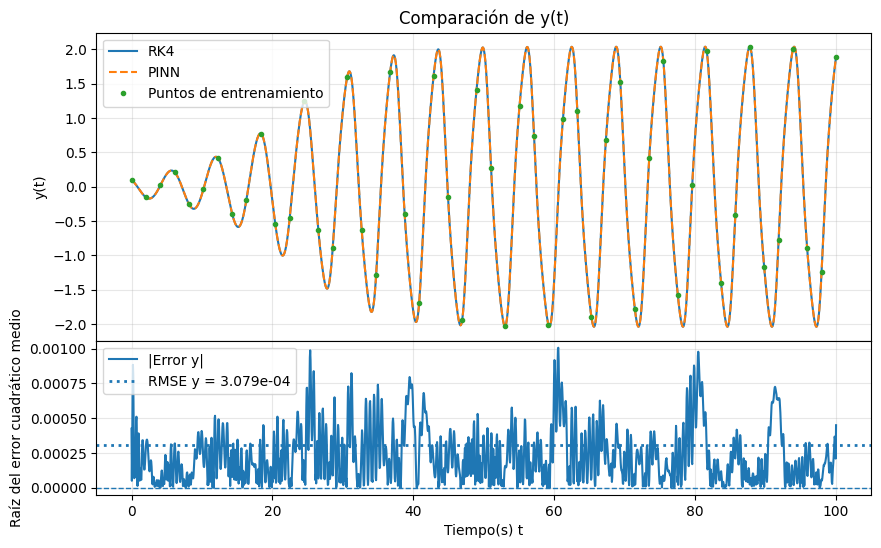

In [13]:
# @title
# ============================================================
# 10. Comparación final RK4 vs PINN
# ============================================================

model.eval()

# Usamos todos los puntos originales para evaluar la PINN
t_eval = tlist.reshape(-1, 1).to(device)
tau_eval = normalize_t(t_eval).to(device)

with torch.no_grad():
    pred_eval = model(tau_eval)
    x_pinn, y_pinn = split_pred(pred_eval)

# Pasamos todo a CPU para comparar y graficar
x_pinn_cpu = x_pinn.detach().cpu()
y_pinn_cpu = y_pinn.detach().cpu()

x_ref_cpu = xlist.reshape(-1, 1).detach().cpu()
y_ref_cpu = ylist.reshape(-1, 1).detach().cpu()
t_cpu = tlist.detach().cpu()

# RMSE contra la solución RK4 completa
rmse_x = torch.sqrt(torch.mean((x_pinn_cpu - x_ref_cpu)**2)).item()
rmse_y = torch.sqrt(torch.mean((y_pinn_cpu - y_ref_cpu)**2)).item()

print(f"RMSE x: {rmse_x:.5e}".replace(".", ","))
print(f"RMSE y: {rmse_y:.5e}".replace(".", ","))

#Error
error_x = x_ref_cpu - x_pinn_cpu
error_y = y_ref_cpu - y_pinn_cpu

mae_x = torch.mean(torch.abs(error_x)).item()
mae_y = torch.mean(torch.abs(error_y)).item()

max_error_x = torch.max(torch.abs(error_x)).item()
max_error_y = torch.max(torch.abs(error_y)).item()

# ------------------------------------------------------------
# Nombres para guardar imágenes
# ------------------------------------------------------------


base = f"S{SEED}_NDP{n_data_points}_H{hidden}_L{layers}_NF{n_frequencies}_MODE{selection_mode}"
if guardar:
    os.makedirs(base, exist_ok=True)

namex = f"X_{base}.png"
namey = f"Y_{base}.png"
namerrx = f"ERRX_{base}.png"
namerry = f"ERRY_{base}.png"

# ------------------------------------------------------------
# Gráfica x(t)
# ------------------------------------------------------------

fig, axs = plt.subplots(
    2, 1,
    figsize=(10, 6),
    sharex=True,
    gridspec_kw={
        "height_ratios": [2, 1],  # gráfica superior más grande
        "hspace": 0.00            # espacio vertical entre gráficas
    }
)

axs[0].plot(t_cpu.numpy(), x_ref_cpu.numpy(), label="RK4")
axs[0].plot(t_cpu.numpy(), x_pinn_cpu.numpy(), "--", label="PINN")
axs[0].plot(t_raw.detach().cpu().numpy(),x_train.detach().cpu().numpy(),"o",ms=3,label="Puntos de entrenamiento")
axs[0].set_ylabel("x(t)")
axs[0].set_title("Comparación de x(t)", pad=6)
axs[0].legend()
axs[0].grid(True, alpha=0.3)

axs[0].tick_params(labelbottom=False)

# ------------------------------------------------------------
# Error promedio absoluto en x(t)
# ------------------------------------------------------------

axs[1].plot(t_cpu.numpy(), torch.abs(error_x).numpy(), label="|Error x|")
axs[1].axhline(0, linestyle="--", linewidth=1)

# Línea del error promedio absoluto
axs[1].axhline(rmse_x, linestyle=":", linewidth=2,
            label=f"RMSE x = {rmse_x:.5e}")

axs[1].set_xlabel("Tiempo(s) t")
axs[1].set_ylabel("Raíz del error cuadrático medio")
#axs[1].set_title("Error absoluto en x(t)")
axs[1].legend()
axs[1].grid(True, alpha=0.3)

if guardar:
  plt.savefig(f"{base}/{namex}", dpi=300, bbox_inches="tight")
  #files.download(namex)

plt.show()

# ------------------------------------------------------------
# Gráfica y(t)
# ------------------------------------------------------------
mae_y = torch.mean(torch.abs(error_y))

fig, axs = plt.subplots(
    2, 1,
    figsize=(10, 6),
    sharex=True,
    gridspec_kw={
        "height_ratios": [2, 1],  # gráfica superior más grande
        "hspace": 0.00            # espacio vertical entre gráficas
    }
)

axs[0].plot(t_cpu.numpy(), y_ref_cpu.numpy(), label="RK4")
axs[0].plot(t_cpu.numpy(), y_pinn_cpu.numpy(), "--", label="PINN")
axs[0].plot(t_raw.detach().cpu().numpy(),y_train.detach().cpu().numpy(),"o",ms=3,label="Puntos de entrenamiento")
axs[0].set_ylabel("y(t)")
axs[0].set_title("Comparación de y(t)", pad=6)
axs[0].legend()
axs[0].grid(True, alpha=0.3)

axs[0].tick_params(labelbottom=False)

# ------------------------------------------------------------
# Error promedio absoluto en y(t)
# ------------------------------------------------------------

axs[1].plot(t_cpu.numpy(), torch.abs(error_y).numpy(), label="|Error y|")
axs[1].axhline(0, linestyle="--", linewidth=1)

# Línea del error promedio absoluto
axs[1].axhline(rmse_y, linestyle=":", linewidth=2,
            label=f"RMSE y = {rmse_y:.3e}")

axs[1].set_xlabel("Tiempo(s) t")
axs[1].set_ylabel("Raíz del error cuadrático medio")
#axs[1].set_title("Error absoluto en y(t)")
axs[1].legend()
axs[1].grid(True, alpha=0.3)

if guardar:
  plt.savefig(f"{base}/{namey}", dpi=300, bbox_inches="tight")
  #files.download(namey)

plt.show()

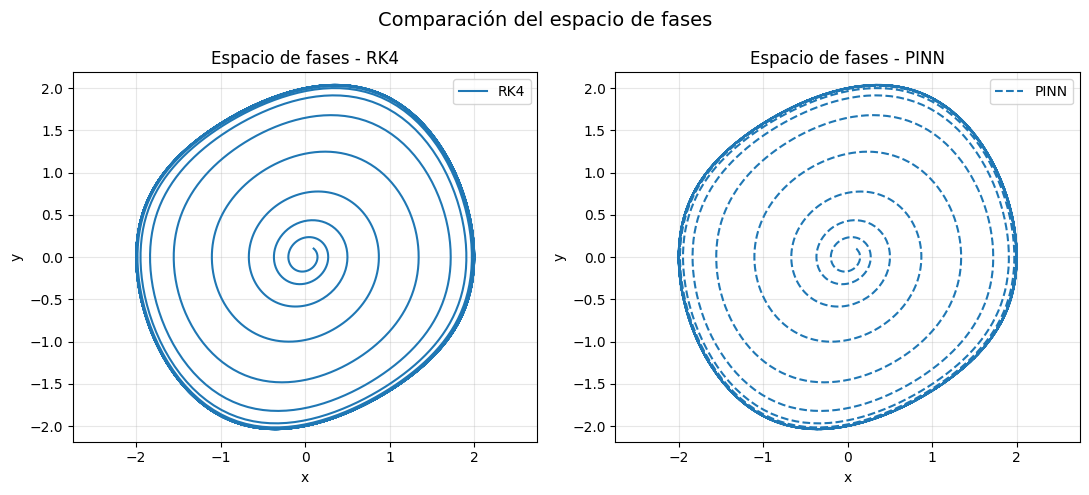

In [14]:
# @title
# ============================================================
# 11. Espacio de fases: RK4 vs PINN
# ============================================================

namesp = f"SP_COMPARACION_{base}.png"

# Convertir a numpy de forma segura
x_rk4 = xlist.detach().cpu().numpy() if torch.is_tensor(xlist) else xlist
y_rk4 = ylist.detach().cpu().numpy() if torch.is_tensor(ylist) else ylist

x_pinn = x_pinn_cpu.detach().cpu().numpy() if torch.is_tensor(x_pinn_cpu) else x_pinn_cpu
y_pinn = y_pinn_cpu.detach().cpu().numpy() if torch.is_tensor(y_pinn_cpu) else y_pinn_cpu

fig, axs = plt.subplots(1, 2, figsize=(11, 5))

# ------------------------------------------------------------
# Gráfica RK4
# ------------------------------------------------------------
axs[0].plot(x_rk4, y_rk4, label="RK4")
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].set_title("Espacio de fases - RK4")
axs[0].legend()
axs[0].grid(True, alpha=0.3)
axs[0].axis("equal")

# ------------------------------------------------------------
# Gráfica PINN
# ------------------------------------------------------------
axs[1].plot(x_pinn, y_pinn, "--", label="PINN")
axs[1].set_xlabel("x")
axs[1].set_ylabel("y")
axs[1].set_title("Espacio de fases - PINN")
axs[1].legend()
axs[1].grid(True, alpha=0.3)
axs[1].axis("equal")

# Título general
fig.suptitle("Comparación del espacio de fases", fontsize=14)

# Ajustar espacios
plt.tight_layout()

if guardar:
    plt.savefig(f"{base}/{namesp}", dpi=300, bbox_inches="tight")
    #files.download(namesp)

plt.show()

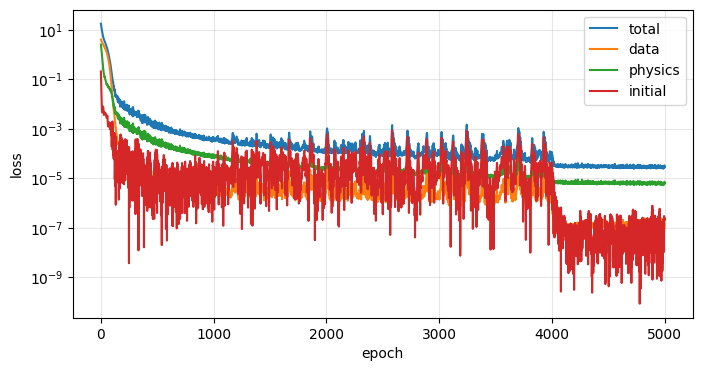

In [15]:
# @title
# ============================================================
# 12. Historial de pérdidas
# ============================================================
namelosses = f"LOSSH_{base}.png"

if len(history["epoch"]) > 0:
    plt.figure(figsize=(8, 4))
    plt.semilogy(history["epoch"], history["loss_total"], label="total")
    plt.semilogy(history["epoch"], history["loss_data"], label="data")
    plt.semilogy(history["epoch"], history["loss_physics"], label="physics")
    plt.semilogy(history["epoch"], history["loss_initial"], label="initial")
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    if guardar:
      plt.savefig(f"{base}/{namelosses}", dpi=300, bbox_inches="tight")
      #files.download(namelosses)
    plt.show()